# From a Training Loop to a Production RL Setup

*Rebuild the GRPO training loop from the previous article the way production RL frameworks are built: a separate inference engine, weight synchronisation, separate processes and worker groups, using verl as our example.*

## Motivation

In the [previous article](grpo_manual.ipynb), we built a GRPO training loop in plain PyTorch, and trained a model with it. However, production RL setups don't look like that loop, and the reason is scale.

Our loop trained a 0.5B model, on one GPU, with 64 short responses per step. In production, both the model and the amount of generation are far larger:

* **The model doesn't fit on one GPU.** Training with Adam in mixed precision takes about 16 bytes per parameter (the weights, their gradients, and the optimizer's state), so a 70B model needs over a terabyte, whereas an H100 has 80 GB. The weights and the optimizer state have to be split across many GPUs.
* **Generation dominates.** Each step samples thousands of responses, often thousands of tokens long, or many turns long for an agent. Even in our small loop, generating took most of each step; at this scale, generation needs a dedicated, much faster engine, with GPUs of its own.
* **The two jobs need different things.** Training needs memory for gradients and optimizer state, whereas generation needs memory for the key/value cache of thousands of sequences at once. These can be run as separate roles, on separate processes, and often separate GPUs.

So, in a production setup, generation runs on a separate inference engine, the weights have to be copied over to it after every update, and the work is split across many processes and GPUs, all coordinated by a framework with hundreds of config options. These are the parts that decide how fast training runs, what breaks, and where to look when it does.

To understand them, we'll take the same approach as before: starting from our training loop, we'll build each part ourselves, see what problem it solves, and then swap in the equivalent from a real framework. As our example, we'll use [verl](https://github.com/volcengine/verl), which is widely used for RL on LLMs, but the same pieces show up, under different names, in other RL frameworks.

## What this article covers

1. Why do production setups generate with a separate inference engine, and what does that change? (§1)
2. How are the inference engine's weights kept up to date? (§2)
3. Why are the log-probs recomputed, when the inference engine has already given them to us? (§3)
4. Why is the work split into separate processes, and how does a batch move between them? (§4)
5. How is the work spread across many workers? (§5)
6. What does it look like when a real framework runs all of this? (§6)

We'll keep the task, the model and the algorithm from the previous article: three-term arithmetic, Qwen2.5-0.5B-Instruct, and GRPO. This way, anything that changes in this article is down to how the training is run, not what is trained.

**What we need to know already.** The previous article: log-probs (§1.3), GRPO advantages (§1.5–§1.6), the batch layout (§1.7), π_old and PPO's clipped loss (§1.9), and verl's versions of our functions (§2). Its code is imported here from `tutorial/lib/rl_core.py`.

**Hardware and time.** One GPU with about 80 GB, and about 7 minutes on an H100, most of it in the training runs of §2 and §6.

## 0. Setup

The functions we wrote in the previous article are imported from `tutorial/lib/rl_core.py`, where they are copied verbatim.

In [1]:
import gc
import json
import os
import random
import re
import shutil
import subprocess
import sys
import time
from pathlib import Path
from pprint import pprint

REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "examples" / "calc_x").is_dir())
sys.path.insert(0, str(REPO / "tutorial/lib"))  # shared code: paths, the model name, the seed
from common import DEVICE, GENERATED, MODEL, SEED, SHM, WORK, follow_log, gpu_free_gib, log_tail, setup, start_service  # noqa: E402

setup()  # creates the working folders, seeds the random number generators, checks the GPU is free

import matplotlib.pyplot as plt  # noqa: E402
import numpy as np  # noqa: E402
import pandas as pd  # noqa: E402
import torch  # noqa: E402
from transformers import AutoTokenizer  # noqa: E402
from verl.trainer.ppo.core_algos import compute_grpo_outcome_advantage  # noqa: E402
from vllm import LLM, SamplingParams, TokensPrompt  # noqa: E402

from arith_task import BOXED, reward_fn  # noqa: E402
from rl_core import (EVAL, INSTRUCTION, LR, PAD_ID, STOP_IDS, TRAIN, chat_prompt_ids, compute_log_probs, decode_tokens,  # noqa: E402
                     evaluate, left_pad, load_policy, make_optimizer, make_padded_batch, plot_histories, ppo_update,
                     print_step_metrics, truncate_at_stop, verl_ppo_loss)

repo: /home/azureuser/localfiles/agl-rl-tutorials
python: /home/azureuser/localfiles/agl-rl-tutorials/.venv/bin/python
GPU: NVIDIA H100 NVL, 46 of 93 GiB free
WARNING 11-17 15:18:52 [config.py:70] Support for Transformers v4 is deprecated. The Transformers v4 codepath will become unmaintained in vLLM v0.22.0 and will be removed in vLLM v0.24.0. Please upgrade to Transformers v5: pip install --upgrade transformers


## 1. A separate inference engine

At the end of the previous article, generating a step's 64 samples with `hf_generate` took about 6 s, whereas computing π_old and updating the weights took just over 1 s between them. So, our training loop spends most of its time generating, and for bigger models and longer responses, the gap only grows. This is why every production RL setup hands generation to a dedicated **inference engine**, such as [vLLM](https://docs.vllm.ai) or [SGLang](https://docs.sglang.ai); here, we'll use vLLM.

To see why this helps, let's look again at `hf_generate`, from §1.7 of the previous article, which generates with Hugging Face's `model.generate`:

In [ ]:
def hf_generate(model, prompts: list[list[int]], samples_per_prompt: int, max_new_tokens: int = 256, greedy: bool = False) -> list[dict]:
    '''samples_per_prompt responses to each prompt, all generated together. Prompt-major: prompt 0's samples come first.'''
    row_prompts = [prompt for prompt in prompts for _ in range(samples_per_prompt)]  # one row per sample
    input_ids, attention_mask = left_pad(row_prompts)
    prompt_width = input_ids.shape[1]

    if greedy:  # always the most likely token: for evaluation
        sampling_settings = {"do_sample": False}
    else:       # a true sample from π: for training
        sampling_settings = {"do_sample": True, "temperature": 1.0, "top_p": 1.0, "top_k": 0, "repetition_penalty": 1.0}

    model.eval()  # inference mode while generating; back to training mode afterwards
    with torch.no_grad(), torch.autocast("cuda", dtype=torch.bfloat16):
        output_ids = model.generate(
            input_ids=input_ids.to(DEVICE), attention_mask=attention_mask.to(DEVICE),
            max_new_tokens=max_new_tokens, pad_token_id=PAD_ID, use_cache=True, **sampling_settings,
        )
    model.train()

    samples = []
    for prompt, output_row in zip(row_prompts, output_ids.tolist()):
        response_ids = truncate_at_stop(output_row[prompt_width:])  # the response starts after the (padded) prompt
        samples.append({"prompt_ids": prompt, "response_ids": response_ids, "log_probs": None})  # HF doesn't give us log-probs
    return samples

The `model.generate` call in the middle does the bulk of the work. It moves the whole batch forward together, one token per step, until the longest response is finished. The diagram below shows this for a batch of three sequences, A, B and C, where each square is one generated token:

![Static batching: once B and C finish, their slots sit idle until A, the longest response, is done](images/static_batching.png)

This is inefficient in several ways:

* **Finished rows sit idle.** A response that stops after 50 tokens keeps its place in the batch until the longest response finishes.
* **Memory is reserved up front.** Each row's key/value (KV) cache, the attention state for the tokens so far, is allocated as one block, big enough for the longest possible response. This limits how many rows fit on the GPU at once.
* **Python overhead on every token.** Each new token launches hundreds of small GPU kernels from Python.

vLLM addresses each of these:

* **Continuous batching:** as soon as one sequence finishes, a waiting one takes its place, so the GPU is always working on a full batch.
* **PagedAttention:** the KV cache is stored in small, fixed-size blocks, which are handed out as each sequence grows, like pages of virtual memory. Nothing is reserved for tokens that never get written, so far more sequences fit at once.
* **CUDA graphs:** the GPU work for one decoding step is recorded once and replayed, which skips the per-token launch overhead.

Here is continuous batching on the same three sequences, with two more, D and E, waiting for a free slot:

![Continuous batching: D and E take over the slots as soon as B and C finish, so no slot sits idle](images/continuous_batching.png)

However, as soon as generation moves out of our training loop, two things change. Firstly, there are now **two copies of the weights**. vLLM doesn't run our PyTorch model: it loads the checkpoint into its own implementation of the model, in bf16, with some layers merged and its own GPU kernels, so that it can generate quickly. So, we have the copy we train, and the copy vLLM generates with. We'll deal with this in §2. Secondly, vLLM has its own **sampling defaults**, which we'll look at shortly.

Let's start from the original model: the policy and optimizer, loaded with the previous article's `load_policy` and `make_optimizer`, and a vLLM engine on the same GPU. We give vLLM 30% of the GPU's memory, for its own copy of the weights and its KV cache.

In [2]:
MODEL

'Qwen/Qwen2.5-0.5B-Instruct'

In [6]:
policy = load_policy()  # the original weights, with gradient checkpointing
optimizer = make_optimizer(policy, LR)

llm = LLM(model=MODEL, gpu_memory_utilization=0.3, max_model_len=4096, seed=SEED)
print('\n')
pprint("vLLM's default sampling params for this model:", llm.get_default_sampling_params())

WARNING 11-17 15:18:31 [config.py:70] Support for Transformers v4 is deprecated. The Transformers v4 codepath will become unmaintained in vLLM v0.22.0 and will be removed in vLLM v0.24.0. Please upgrade to Transformers v5: pip install --upgrade transformers
(EngineCore pid=123088) ERROR 11-17 15:18:33 [core.py:1165] EngineCore failed to start.
(EngineCore pid=123088) ERROR 11-17 15:18:33 [core.py:1165] Traceback (most recent call last):
(EngineCore pid=123088) ERROR 11-17 15:18:33 [core.py:1165]   File "/home/azureuser/localfiles/agl-rl-tutorials/.venv/lib/python3.12/site-packages/vllm/v1/engine/core.py", line 1139, in run_engine_core
(EngineCore pid=123088) ERROR 11-17 15:18:33 [core.py:1165]     engine_core = EngineCoreProc(*args, engine_index=dp_rank, **kwargs)
(EngineCore pid=123088) ERROR 11-17 15:18:33 [core.py:1165]                   ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
(EngineCore pid=123088) ERROR 11-17 15:18:33 [core.py:1165]   File "/home/azureuser/localfile

(EngineCore pid=123088) Process EngineCore:
(EngineCore pid=123088) Traceback (most recent call last):
(EngineCore pid=123088)   File "/home/azureuser/.local/share/uv/python/cpython-3.12.15-linux-x86_64-gnu/lib/python3.12/multiprocessing/process.py", line 314, in _bootstrap
(EngineCore pid=123088)     self.run()
(EngineCore pid=123088)   File "/home/azureuser/.local/share/uv/python/cpython-3.12.15-linux-x86_64-gnu/lib/python3.12/multiprocessing/process.py", line 108, in run
(EngineCore pid=123088)     self._target(*self._args, **self._kwargs)
(EngineCore pid=123088)   File "/home/azureuser/localfiles/agl-rl-tutorials/.venv/lib/python3.12/site-packages/vllm/v1/engine/core.py", line 1169, in run_engine_core
(EngineCore pid=123088)     raise e
(EngineCore pid=123088)   File "/home/azureuser/localfiles/agl-rl-tutorials/.venv/lib/python3.12/site-packages/vllm/v1/engine/core.py", line 1139, in run_engine_core
(EngineCore pid=123088)     engine_core = EngineCoreProc(*args, engine_index=dp_ran

RuntimeError: Engine core initialization failed. See root cause above. Failed core proc(s): {}

#### Sampling settings

In the previous article (§1.2), we saw that `generate` takes any sampling parameter we don't pass from the model's `generation_config.json`, which for Qwen2.5-0.5B-Instruct means `temperature=0.7, top_p=0.8, top_k=20, repetition_penalty=1.1`. These settings make chat responses read well, but they change the distribution that the tokens are sampled from, so the samples are no longer draws from π.

As we can see from the warning and the printed defaults above, vLLM does exactly the same thing. To see how much this matters, let's sample 8 responses to the same question twice, once with vLLM's defaults and once with our RL settings, and then score both sets with our training model:

In [ ]:
chat_settings = SamplingParams(n=8, max_tokens=128)  # vLLM's defaults, taken from the model's generation_config.json
rl_settings = SamplingParams(n=8, temperature=1.0, top_p=1.0, top_k=0, repetition_penalty=1.0, max_tokens=128)

test_prompt = chat_prompt_ids(TRAIN[0]["question"])
chat_outputs = llm.generate([TokensPrompt(prompt_token_ids=test_prompt)], chat_settings, use_tqdm=False)
rl_outputs = llm.generate([TokensPrompt(prompt_token_ids=test_prompt)], rl_settings, use_tqdm=False)


def mean_log_prob_per_token(outputs) -> torch.Tensor:
    # Score vLLM's samples with our training model: one mean log π per token for each sample
    response_ids = [list(completion.token_ids) for completion in outputs[0].outputs]
    batch = make_padded_batch([test_prompt] * len(response_ids), response_ids)
    log_probs = compute_log_probs(policy, batch)
    mask = batch["response_mask"]
    return (log_probs * mask).sum(-1) / mask.sum(-1)


chat_log_prob = mean_log_prob_per_token(chat_outputs).mean()
rl_log_prob = mean_log_prob_per_token(rl_outputs).mean()

print(f"mean log π per token, vLLM's defaults: {chat_log_prob:.3f}")
print(f"mean log π per token, RL settings:     {rl_log_prob:.3f}")
print(f"per token, samples with vLLM's defaults are {torch.exp(chat_log_prob - rl_log_prob):.2f}× more likely under π")

(EngineCore pid=200664) WARNING 11-16 15:11:16 [jit_monitor.py:103] Triton kernel JIT compilation during inference: _compute_slot_mapping_kernel. This causes a latency spike; consider extending warmup to cover this shape/config.


mean log π per token, vLLM's defaults: -0.248
mean log π per token, RL settings:     -0.290
per token, samples with vLLM's defaults are 1.04× more likely under π


As we would expect from the previous article, the samples with vLLM's defaults are made up of tokens that π finds more likely than usual, as `top_k` and `top_p` throw away the unlikely ones before sampling. Per token, the difference looks small: 1.04× in our run, or 0.04 in log π. However, a response is about 150 tokens long, and the per-token factors multiply, so a whole response sampled with the defaults is about e^(0.04 × 150) ≈ e^6, or several hundred times, more likely under π than a true sample. Training on these would mean learning from responses that the model would hardly ever write itself.

So, as with `hf_generate`, we always pass the RL settings explicitly. Production frameworks do the same: verl overrides the generation config when it starts vLLM. If we instead run vLLM as a server, the flag `--generation-config vllm` tells it to ignore the model's defaults.

#### Generating with vLLM

We can now write `vllm_generate`, which returns samples in the same format as the previous article's `hf_generate`, so that the rest of our training loop doesn't need to change. It passes our RL settings, along with `logprobs=0`, which asks vLLM to also return the log-prob of each token it sampled (the number is how many *extra* alternatives to return, so 0 means none).

vLLM's output is nested, one level per prompt and one per sample:

```
request_outputs                      one per prompt
 └─ request_output.outputs           samples_per_prompt completions for that prompt
     ├─ completion.token_ids         the sampled response tokens
     └─ completion.logprobs          one dict per position: {sampled_token_id: Logprob(logprob=-0.03, ...)}
```

For each completion, we look up the sampled token in each position's dict to get its log-prob. 

This is something `hf_generate` didn't give us: there, the only log-probs we had were the ones we computed afterwards, with a separate forward pass over the finished batch (`compute_log_probs`, for π_old). vLLM records each token's log-prob as it samples it, and we'll compare these with our training model's in §3. (vLLM computes them from the model's raw scores, before temperature is applied, so they only match the sampling distribution at temperature 1; as we always sample at temperature 1, this is fine.)

In [ ]:
def vllm_generate(llm, prompts: list[list[int]], samples_per_prompt: int, max_tokens: int = 256, temperature: float = 1.0) -> list[dict]:
    # logprobs=0: return the log-prob of each sampled token (and no alternatives)
    params = SamplingParams(n=samples_per_prompt, temperature=temperature, top_p=1.0, top_k=0, repetition_penalty=1.0, max_tokens=max_tokens, logprobs=0)
    
    token_prompts = [TokensPrompt(prompt_token_ids=prompt) for prompt in prompts]
    request_outputs = llm.generate(token_prompts, params, use_tqdm=False)
    samples = []
    
    for prompt, request_output in zip(prompts, request_outputs):
        for completion in request_output.outputs:  # samples_per_prompt completions per prompt
            response_ids = list(completion.token_ids)
            
            # completion.logprobs holds one {token_id: Logprob} dict per position; look up the token that was sampled
            log_probs = []
            
            for token_id, logprobs_at_position in zip(response_ids, completion.logprobs):
                log_probs.append(logprobs_at_position[token_id].logprob)
            
            samples.append({"prompt_ids": list(prompt), "response_ids": response_ids, "log_probs": log_probs})
    
    return samples

Let's compare the two on the same job: 8 samples for each of the first 8 training questions, as in the previous article.

In [5]:
prompts = [chat_prompt_ids(problem["question"]) for problem in TRAIN[:8]]

start = time.time()
hf_samples = hf_generate(policy, prompts, samples_per_prompt=8)
print(f"hf_generate:   {len(hf_samples)} samples in {time.time() - start:5.2f}s")

start = time.time()
vllm_samples = vllm_generate(llm, prompts, samples_per_prompt=8)
print(f"vllm_generate: {len(vllm_samples)} samples in {time.time() - start:5.2f}s")

finished = [sample["response_ids"][-1] in STOP_IDS for sample in vllm_samples]
print(f"vLLM samples that end with a stop token: {np.mean(finished):.0%}")

hf_generate:   64 samples in  7.37s


vllm_generate: 64 samples in  0.81s
vLLM samples that end with a stop token: 94%


As we can see, vLLM generated the same number of samples about 9 times faster, and the gap grows with the batch size; a production RL step often generates thousands of samples.

Most of vLLM's samples (94% in our run) end with a stop token; the rest were cut off by our 256-token limit, just as with `hf_generate`.

## 2. Keeping the weights in sync

Our training loop updates its own copy of the weights, but vLLM generates with its copy, which never changes on its own. So, after every update, we need to copy the new weights over to vLLM; otherwise, the next batch would be sampled from an older version of the policy, while the training assumes it was sampled from the current one. We'll see what this looks like in §3.

The simplest way of doing this has two parts:

1. The training loop writes its weights to a file, in the Hugging Face checkpoint format. Any folder would do; we use `/dev/shm`, which Linux keeps in RAM, so nothing has to be written to disk. We convert the weights to bf16 on the way, as vLLM computes in bf16 anyway, and doesn't need our fp32 copy. This is known as the **data plane**: the part that moves the bulk of the bytes.
2. A small message, `collective_rpc("reload_weights", ...)`, tells vLLM to load the weights from that folder. This is the **control plane**: "new weights are ready, and this is where they are".

There is one more detail. vLLM keeps a **prefix cache**: when a new prompt starts with tokens it has already processed, it reuses the KV cache it computed for them. Every one of our prompts starts with the same system prompt and chat-template tokens, so this saves a lot of work. However, those cached values were computed with the *old* weights, and vLLM would keep reusing them, as the tokens still match. So, after loading new weights, we also reset the prefix cache.

In [ ]:
import safetensors.torch

def push_weights(model, llm) -> None:
    weights_path = save_for_inference(model)                                     # 1. data plane: write the weights to RAM
    llm.collective_rpc("reload_weights", kwargs={"weights_path": weights_path})  # 2. control plane: tell vLLM to load them
    llm.reset_prefix_cache()  # cached KV values were computed with the old weights


def save_for_inference(model, path: Path = SHM / "policy") -> str:
    path.mkdir(parents=True, exist_ok=True)
    state = {}
    
    for name, tensor in model.state_dict().items():
        state[name] = tensor.detach().to(torch.bfloat16).cpu().contiguous()  # a bf16 copy on the CPU, ready to write
    
    if model.config.tie_word_embeddings:
        state.pop("lm_head.weight", None)  # same tensor as the embedding; vLLM ties them itself
    
    safetensors.torch.save_file(state, str(path / "model.safetensors"))
    return str(path)


Production frameworks follow the same structure, but skip the round trip through the CPU. verl, for example, sends the bf16 tensors directly from the training GPUs' memory to vLLM: over CUDA IPC when both are on the same GPU, or over NCCL when they're on different GPUs, in buckets of a fixed size, so that the whole model never has to be copied at once.

As our policy and vLLM both loaded the original checkpoint, they already agree; we'll sync once anyway, to check that it works. Then, as in the previous article (§1.8), we measure greedy accuracy on the 200 held-out questions, this time with vLLM doing the generation:

In [7]:
def vllm_sample(prompts, samples_per_prompt):
    return vllm_generate(llm, prompts, samples_per_prompt)


def vllm_greedy(prompts, samples_per_prompt):
    return vllm_generate(llm, prompts, samples_per_prompt, temperature=0.0)  # temperature 0: always the most likely token


start = time.time()
push_weights(policy, llm)
print(f"weights pushed in {time.time() - start:.1f}s")

accuracy_before = evaluate(vllm_greedy)
print(f"greedy accuracy on {len(EVAL)} held-out problems, before training: {accuracy_before:.3f}")

(EngineCore pid=200664) 
Loading safetensors checkpoint shards:   0% Completed | 0/1 [00:00<?, ?it/s]
(EngineCore pid=200664) 
Loading safetensors checkpoint shards: 100% Completed | 1/1 [00:00<00:00,  5.13it/s]
(EngineCore pid=200664) 
Loading safetensors checkpoint shards: 100% Completed | 1/1 [00:00<00:00,  5.13it/s]
(EngineCore pid=200664) 


(EngineCore pid=200664) WARNING 11-16 15:11:26 [layerwise.py:253] RotaryEmbedding: Failed to load weights
weights pushed in 1.2s


greedy accuracy on 200 held-out problems, before training: 0.735


(vLLM prints a "RotaryEmbedding: Failed to load weights" warning when it reloads; this is harmless, as the rotary position embedding has no trained weights to load.)

The accuracy is a little different from the 0.765 we measured with `hf_generate` in the previous article. vLLM and Hugging Face use different GPU kernels, which round slightly differently (§1.7 of the previous article), and with greedy decoding, a tiny difference at a near-tie between two tokens can send a response down a different path.

#### Training with vLLM generating

Now, let's train with vLLM doing the generation. Our training step is the previous article's `rl_step`, with one addition at the end: as vLLM gives us its own log-prob for every token it sampled, we compare them with the log-probs our training model computes for π_old, and report the average difference as `logp_mismatch`. We'll look at what this tells us in §3.

In [ ]:
def rl_step(policy, optimizer, generate, problems, samples_per_prompt: int = 8, **update_kwargs) -> tuple[dict, dict, list[dict]]:
    timing = {}

    # 1. Sample several responses per problem (a GRPO group). Samples are prompt-major: sample i answers problem i // samples_per_prompt
    start = time.time()
    samples = generate([chat_prompt_ids(problem["question"]) for problem in problems], samples_per_prompt)
    timing["gen"] = time.time() - start
    group_ids = [i // samples_per_prompt for i in range(len(samples))]

    # 2. Score each response, then pad everything into one batch (for π_old, the advantages and the update)
    texts = [decode_tokens(sample["response_ids"]) for sample in samples]
    rewards = torch.tensor([reward_fn(text, problems[group]["answer"]) for text, group in zip(texts, group_ids)])
    batch = make_padded_batch([sample["prompt_ids"] for sample in samples], [sample["response_ids"] for sample in samples])

    # π_old: log-probs under the weights that generated the samples (§1.9)
    start = time.time()
    old_log_probs = compute_log_probs(policy, batch)
    timing["old_log_prob"] = time.time() - start

    # 3. Advantages with verl's GRPO estimator, which takes each response's reward on its last token
    last_token = batch["response_mask"].sum(-1).clamp(min=1) - 1
    token_level_rewards = torch.zeros(batch["response_mask"].shape)
    token_level_rewards[torch.arange(len(samples)), last_token] = rewards
    
    advantages, _ = compute_grpo_outcome_advantage(
        token_level_rewards=token_level_rewards, response_mask=batch["response_mask"], index=np.array(group_ids, dtype=object),
    )
    batch.update(old_log_probs=old_log_probs, advantages=advantages)  # kept for inspection after the update

    # 4. Update: PPO, with verl's loss
    start = time.time()
    stats = ppo_update(policy, optimizer, batch, old_log_probs, advantages, loss_fn=verl_ppo_loss, **update_kwargs)
    timing["update"] = time.time() - start

    metrics = {
        "reward": rewards.mean().item(),
        "format": float(np.mean([bool(BOXED.search(text)) for text in texts])),  # has a \boxed{integer} at all, right or wrong
        "response_len": batch["response_mask"].sum(-1).float().mean().item(),
        **stats,
    }
    
    if samples[0]["log_probs"] is not None:  # the inference engine returned its own log-probs: compare them with ours
        engine_log_probs = torch.zeros_like(old_log_probs)
    
        for row, sample in enumerate(samples):
            engine_log_probs[row, : len(sample["log_probs"])] = torch.tensor(sample["log_probs"])
    
        trained = batch["response_mask"].bool()
        metrics["logp_mismatch"] = (old_log_probs - engine_log_probs)[trained].abs().mean().item()
    
    metrics.update({f"time/{name}": seconds for name, seconds in timing.items()})
    
    return metrics, batch, samples

Let's train for 20 steps, starting from the original model. As generation is now cheap, each step uses twice as many questions as before: 16 questions × 8 samples = 128 samples. `ppo_update` splits them into 2 mini-batches of 64, so each step takes 2 optimizer steps, as in §1.9 of the previous article. After every step, we push the new weights to vLLM, and time how long that takes as `sync`.

The step line is the same as before, with two additions: `logp mismatch`, and the time taken by `sync`.

In [9]:
NUM_STEPS = 20
QUESTIONS_PER_STEP = 16

question_rng = random.Random(SEED)  # which training questions each step uses
vllm_history = []

for step in range(NUM_STEPS):
    problems = question_rng.sample(TRAIN, QUESTIONS_PER_STEP)
    metrics, batch, samples = rl_step(policy, optimizer, vllm_sample, problems)

    start = time.time()
    push_weights(policy, llm)  # vLLM must generate the next step's samples with the new weights
    metrics["time/sync"] = time.time() - start

    vllm_history.append(metrics)
    print_step_metrics(step, metrics)

accuracy_after = evaluate(vllm_greedy)
print(f"\ngreedy accuracy on held-out problems: {accuracy_before:.3f} before -> {accuracy_after:.3f} after {NUM_STEPS} steps")

(EngineCore pid=200664) 
Loading safetensors checkpoint shards:   0% Completed | 0/1 [00:00<?, ?it/s]
(EngineCore pid=200664) 
Loading safetensors checkpoint shards: 100% Completed | 1/1 [00:00<00:00,  5.34it/s]
(EngineCore pid=200664) 
Loading safetensors checkpoint shards: 100% Completed | 1/1 [00:00<00:00,  5.33it/s]
(EngineCore pid=200664) 


(EngineCore pid=200664) WARNING 11-16 15:11:33 [layerwise.py:253] RotaryEmbedding: Failed to load weights
step  0 | reward 0.617 | format 0.79 | len 151.1 | grad_norm 2.296 | logp mismatch 0.0092 | gen  0.7s old_log_prob  0.4s update  2.9s sync  1.3s


(EngineCore pid=200664) 
Loading safetensors checkpoint shards:   0% Completed | 0/1 [00:00<?, ?it/s]
(EngineCore pid=200664) 
Loading safetensors checkpoint shards: 100% Completed | 1/1 [00:00<00:00,  5.39it/s]
(EngineCore pid=200664) 
Loading safetensors checkpoint shards: 100% Completed | 1/1 [00:00<00:00,  5.38it/s]
(EngineCore pid=200664) 


(EngineCore pid=200664) WARNING 11-16 15:11:38 [layerwise.py:253] RotaryEmbedding: Failed to load weights
step  1 | reward 0.578 | format 0.80 | len 150.1 | grad_norm 2.239 | logp mismatch 0.0090 | gen  0.7s old_log_prob  0.4s update  2.8s sync  1.3s


(EngineCore pid=200664) 
Loading safetensors checkpoint shards:   0% Completed | 0/1 [00:00<?, ?it/s]
(EngineCore pid=200664) 
Loading safetensors checkpoint shards: 100% Completed | 1/1 [00:00<00:00,  5.34it/s]
(EngineCore pid=200664) 
Loading safetensors checkpoint shards: 100% Completed | 1/1 [00:00<00:00,  5.33it/s]
(EngineCore pid=200664) 


(EngineCore pid=200664) WARNING 11-16 15:11:43 [layerwise.py:253] RotaryEmbedding: Failed to load weights
step  2 | reward 0.648 | format 0.91 | len 152.3 | grad_norm 2.192 | logp mismatch 0.0074 | gen  0.8s old_log_prob  0.4s update  2.8s sync  1.3s


... (31 outputs left out)

(EngineCore pid=200664) WARNING 11-16 15:13:05 [layerwise.py:253] RotaryEmbedding: Failed to load weights
step 18 | reward 0.922 | format 1.00 | len  97.1 | grad_norm 1.433 | logp mismatch 0.0055 | gen  0.5s old_log_prob  0.4s update  2.6s sync  1.3s


(EngineCore pid=200664) 
Loading safetensors checkpoint shards:   0% Completed | 0/1 [00:00<?, ?it/s]
(EngineCore pid=200664) 
Loading safetensors checkpoint shards: 100% Completed | 1/1 [00:00<00:00,  5.37it/s]
(EngineCore pid=200664) 
Loading safetensors checkpoint shards: 100% Completed | 1/1 [00:00<00:00,  5.37it/s]
(EngineCore pid=200664) 


(EngineCore pid=200664) WARNING 11-16 15:13:10 [layerwise.py:253] RotaryEmbedding: Failed to load weights
step 19 | reward 0.688 | format 1.00 | len 100.5 | grad_norm 2.250 | logp mismatch 0.0063 | gen  0.5s old_log_prob  0.4s update  2.6s sync  1.3s



greedy accuracy on held-out problems: 0.735 before -> 0.850 after 20 steps


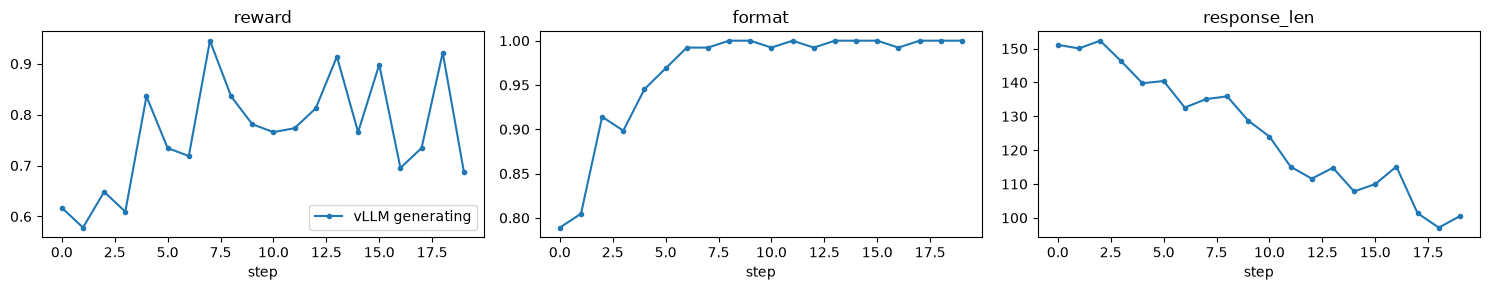

In [10]:
plot_histories({"vLLM generating": vllm_history}, keys=("reward", "format", "response_len"))

Each step now takes about 5 seconds, for twice as many samples as each step in the previous article, and generation has become the smallest part of it: about 0.6 s for 128 samples. The update, at about 2.7 s, now takes up most of each step, followed by the weight sync, at about 1.3 s.

Looking at the plots, the reward goes up from around 0.6 to around 0.8–0.9, noisily, and greedy accuracy on the held-out questions went from 0.735 to 0.850. Notice that the format goes up first: within 8 steps, the share of responses with a `\boxed{}` number went from 79% to 100%. As a response without one always scores 0, learning the format accounts for much of the early rise in reward; after that, the format has nowhere left to go, but the reward keeps improving, so the model is getting more of the arithmetic right too. The responses also get shorter, from about 150 tokens to about 100.

This is a common pattern in RL: the first thing the model learns is usually whatever the reward checks most directly, here the format. So, a big early jump in reward is rarely a jump in ability, which is why it's worth tracking the format separately.

## 3. Do the training model and vLLM agree?

During training, `logp_mismatch` stayed small, between about 0.004 and 0.009. This means that, on average, our training model and vLLM agree very closely on how likely each sampled token is. However, an average can hide a lot, so let's look at the difference for every token in the last batch.

We can also think about this difference in terms of the ratio ρ from §1.9 of the previous article. If we had used vLLM's log-probs as π_old, rather than recomputing them, then e^(difference) is exactly the ratio that the first update would see for each token. Before any update, it should be exactly 1.

12863 trained tokens
mean |difference|:            0.0063
99th percentile |difference|: 0.118
largest |difference|:         0.513
implied ratios before any update: from 0.599 to 1.648


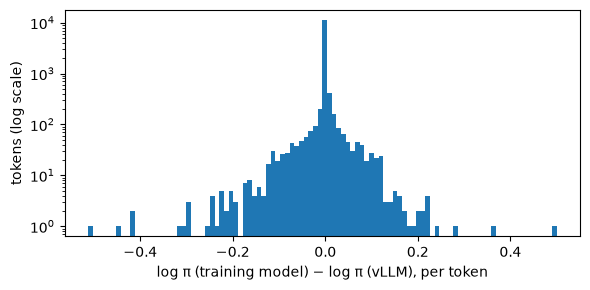

In [11]:
trained = batch["response_mask"].bool()

# vLLM's log-prob of every sampled token, padded to the same shape as the batch
engine_log_probs = torch.zeros_like(batch["old_log_probs"])
for row, sample in enumerate(samples):
    engine_log_probs[row, : len(sample["log_probs"])] = torch.tensor(sample["log_probs"])

difference = (batch["old_log_probs"] - engine_log_probs)[trained]  # log π (training model) − log π (vLLM), one per trained token
print(f"{difference.numel()} trained tokens")
print(f"mean |difference|:            {difference.abs().mean():.4f}")
print(f"99th percentile |difference|: {difference.abs().quantile(0.99):.3f}")
print(f"largest |difference|:         {difference.abs().max():.3f}")
print(f"implied ratios before any update: from {difference.exp().min():.3f} to {difference.exp().max():.3f}")

plt.figure(figsize=(6, 3))
plt.hist(difference.numpy(), bins=100, log=True)
plt.xlabel("log π (training model) − log π (vLLM), per token")
plt.ylabel("tokens (log scale)")
plt.tight_layout()
plt.show()

As we can see, most tokens agree almost exactly, so the mean difference is tiny, about 0.006. However, the distribution has a long tail: in our run, one token in a hundred was off by about 0.12 or more, and the worst by about 0.5. Expressed as ratios, before any update has happened, they range from about 0.6 to 1.65.

This isn't a bug in either program. As we saw in §1.7 of the previous article, bf16 keeps only about 3 significant digits, and vLLM and our training model use different GPU kernels, which add numbers up in a different order, so the rounding comes out differently.

So why does this matter? Let's take a token where our training model gives log π = −2.00, and vLLM gave −2.26. If we used vLLM's number as π_old, then before any update, the ratio would be e^(−2.00 − (−2.26)) = e^0.26 ≈ 1.30. This is already past the clip limit of 1.28, so if the token had a positive advantage, its gradient would be zero: the clip would block an update that never happened, just because two programs compute the same number slightly differently.

This is why our training loop recomputes π_old with the training model (`compute_log_probs`), rather than using vLLM's numbers: the ratio has to compare like with like, so that ρ = 1 exactly before the first update. Production frameworks do the same. verl calls this step `compute_log_prob`; it keeps vLLM's numbers too, as `rollout_log_probs`, and can use the gap between the two to correct the update (`algorithm.rollout_correction`). At scale, this mismatch between training and inference is one of the main sources of instability in RL training, which is why verl can log it at every step, as `rollout_corr/kl`.

#### What if we skip the weight sync?

`logp_mismatch` also tells us whether the weight sync is working. Let's take 5 more training steps, but this time without pushing the new weights to vLLM after each one, and then sync once at the end:

In [12]:
for step in range(5):
    problems = question_rng.sample(TRAIN, QUESTIONS_PER_STEP)
    metrics, batch, samples = rl_step(policy, optimizer, vllm_sample, problems)  # no push_weights: vLLM keeps the old weights
    print_step_metrics(NUM_STEPS + step, metrics)

push_weights(policy, llm)
print("\nweights pushed to vLLM\n")

problems = question_rng.sample(TRAIN, QUESTIONS_PER_STEP)
metrics, batch, samples = rl_step(policy, optimizer, vllm_sample, problems)
push_weights(policy, llm)
print_step_metrics(NUM_STEPS + 5, metrics)

step 20 | reward 0.648 | format 1.00 | len  98.2 | grad_norm 1.172 | logp mismatch 0.0061 | gen  0.5s old_log_prob  0.4s update  2.7s


step 21 | reward 0.977 | format 1.00 | len  94.3 | grad_norm 1.541 | logp mismatch 0.0188 | gen  0.6s old_log_prob  0.4s update  2.8s


step 22 | reward 0.898 | format 1.00 | len 100.5 | grad_norm 1.395 | logp mismatch 0.0329 | gen  0.5s old_log_prob  0.5s update  2.4s


step 23 | reward 0.820 | format 1.00 | len  95.4 | grad_norm 1.756 | logp mismatch 0.0507 | gen  0.6s old_log_prob  0.2s update  2.2s


step 24 | reward 0.688 | format 0.99 | len 102.4 | grad_norm 1.779 | logp mismatch 0.0688 | gen  0.5s old_log_prob  0.2s update  2.2s


(EngineCore pid=200664) 
Loading safetensors checkpoint shards:   0% Completed | 0/1 [00:00<?, ?it/s]
(EngineCore pid=200664) 
Loading safetensors checkpoint shards: 100% Completed | 1/1 [00:00<00:00,  6.02it/s]
(EngineCore pid=200664) 
Loading safetensors checkpoint shards: 100% Completed | 1/1 [00:00<00:00,  6.01it/s]
(EngineCore pid=200664) 


(EngineCore pid=200664) WARNING 11-16 15:13:29 [layerwise.py:253] RotaryEmbedding: Failed to load weights

weights pushed to vLLM



(EngineCore pid=200664) WARNING 11-16 15:13:34 [layerwise.py:253] RotaryEmbedding: Failed to load weights
step 25 | reward 0.875 | format 1.00 | len  93.2 | grad_norm 1.257 | logp mismatch 0.0062 | gen  0.4s old_log_prob  0.2s update  2.5s


(EngineCore pid=200664) 
Loading safetensors checkpoint shards:   0% Completed | 0/1 [00:00<?, ?it/s]
(EngineCore pid=200664) 
Loading safetensors checkpoint shards: 100% Completed | 1/1 [00:00<00:00,  6.29it/s]
(EngineCore pid=200664) 
Loading safetensors checkpoint shards: 100% Completed | 1/1 [00:00<00:00,  6.28it/s]
(EngineCore pid=200664) 


Step 20 still uses samples from up-to-date weights, as we synced after step 19, so its mismatch is the usual 0.006. From then on, each step's samples come from weights that are one more update behind, and the mismatch grows steadily: 0.019, 0.033, 0.051 and 0.069, more than ten times the usual value. As soon as we push the weights again, it drops straight back to 0.006.

Notice that nothing else in the step line tells us that anything is wrong. As we recompute π_old with the training model, every ratio is still exactly 1 before the first update, so the clipped loss can't see the problem either. Yet the samples were drawn from an older policy than the one we're training, so the update is based on responses that the current model would write less often, or not at all. A stale inference engine doesn't crash anything, and `logp_mismatch` (in verl, `rollout_corr/kl`) is how we find out.

#### Stale on purpose: asynchronous training

Our training loop is **synchronous**: each step generates, then updates, then syncs the weights, and only then starts generating again. So, at any moment, one of the two roles is waiting for the other. In our run, vLLM was busy for about 0.6 s of each 5 s step, and idle for the rest. At scale, the imbalance usually runs the other way: generation takes up most of each step, and its time is set by the slowest response in the batch (or, for an agent, the slowest rollout), while the GPUs that do the update sit and wait.

**Asynchronous** training removes the wait by running the two roles at the same time, usually on separate GPUs (the disaggregated layout we'll meet in §4). While the training role updates on one batch, the rollout role is already generating the next, with the weights from before that update:

![Synchronous training alternates generation and updates, so each role sits idle while the other works; one-step-off asynchronous training generates the next batch while the current one is trained on, so batch 2 is generated with the weights from before update 1](images/async_timeline.png)

The cost is exactly what we saw in the experiment above: the samples come from weights that are an update behind. In our run, a single missed update raised `logp_mismatch` from 0.006 to 0.019, and each further one raised it more, so asynchronous setups keep the lag small, typically to a single step.

Within that lag, the stale samples are corrected for, rather than ignored. There are now three versions of the policy: the one that generated the samples (vLLM's, which gave us `rollout_log_probs`), π_old (the training model's weights before this step's update, recomputed by `compute_log_probs` as before), and π_θ, which is being updated. The PPO ratio π_θ / π_old works exactly as before. On top of it, each token's loss is multiplied by an **importance-sampling weight**, π_old / π_rollout = e^(log π_old − log π_rollout), which reweights a sample drawn from the older policy as if it had been drawn from π_old: tokens that π_old finds more likely than the rollout policy did count for more, and tokens it finds less likely count for less. As a few of these weights can be very large, they are capped, typically at 2, which is known as **truncated importance sampling**.

In verl, this is `algorithm.rollout_correction`: `rollout_is="token"` turns on a weight per token, and `rollout_is_threshold` sets the cap (2.0 by default). The same correction also covers the small mismatch between the training model and vLLM that we measured at the start of this section, even with no staleness at all; [*When Speed Kills Stability*](https://richardli.xyz/rl-collapse), referenced in verl's documentation, argues that this mismatch alone can make long training runs collapse.

## 4. Separate processes

So far, a single Python process does everything: it holds the policy, the optimizer and the vLLM engine, and runs the training loop. This is fine for a 0.5B model on one GPU, but in a production setup, these are different **roles**, with very different needs:

* the **rollout** role (vLLM) needs GPUs with plenty of memory for the KV cache, and often many copies of the model, to generate enough samples;
* the **training** role needs the policy and the optimizer state, often split across many GPUs, as a large model and its optimizer don't fit on one;
* other roles, such as a reward model, may need GPUs of their own.

Each role also has its own lifetime: the training role keeps its weights and optimizer state for the whole run, whereas rollout engines can be started, put to sleep to free their memory, and woken up again. So, production frameworks run each role in **separate processes**, and a single **driver** process runs the training loop, telling each role what to do.

Most of them, verl included, use [Ray](https://docs.ray.io) for this. Ray lets one Python script start objects in other processes, on any machine in a cluster, and call their methods almost as if they were local. The main idea we need is the **actor**: a class whose instance lives in its own process, keeping its state (a model, an optimizer) between calls. Calling `actor.method.remote(x)` returns immediately with a *future*, a ticket for a result that doesn't exist yet, and `ray.get(future)` waits for it. Arguments and results travel between processes through Ray's *object store*.

Before we start, let's free the GPU: the vLLM engine and the policy in this process go away, and Ray actors will take over.

In [13]:
llm.llm_engine.engine_core.shutdown()  # vLLM runs its engine in a child process; stop it first
del llm, policy, optimizer
gc.collect()
torch.cuda.empty_cache()
print(f"GPU free: {gpu_free_gib():.0f} GiB")

GPU free: 92 GiB


#### The batch has to travel

Before we split up our training loop, there is one problem to solve. So far, a step's data has been a dict of padded tensors, plus a few things kept in separate variables: each sample's group ID, its question's answer, and vLLM's log-probs. This works when everything happens in one place, but once the batch is sent to other processes and split between workers, every split has to cut the tensors *and* the side lists at exactly the same rows. If we do this by hand in a few places, sooner or later, row 37's reward ends up attached to row 38's response, with no error anywhere.

Production frameworks solve this with a batch container that keeps everything about a row together. verl's is `DataProto`, which has three parts:

* `.batch`: a `TensorDict`, a dict of tensors that all share the first (row) dimension, so they're always sliced together;
* `.non_tensor_batch`: numpy arrays with the same first dimension, for anything that isn't a tensor (group IDs, answers, strings);
* `.meta_info`: a plain dict, for values that apply to the whole batch (the temperature, the step number, …).

Let's build one from the last step's samples, and try the operations that the rest of this article relies on:

In [14]:
from verl import DataProto

proto = DataProto.from_dict(
    tensors=make_padded_batch([sample["prompt_ids"] for sample in samples], [sample["response_ids"] for sample in samples]),
    non_tensors={"uid": np.array([i // 8 for i in range(len(samples))], dtype=object)},  # uid = group: sample i answers question i // 8
    meta_info={"temperature": 1.0},
)
print(f"{len(proto)} rows")
print(f"tensors:     {list(proto.batch.keys())}")
print(f"non-tensors: {list(proto.non_tensor_batch)}")
print(f"meta_info:   {proto.meta_info}\n")

selected = proto[[0, 5, 9]]
print(f"index with a list: {len(selected)} rows, uids {selected.non_tensor_batch['uid'].tolist()}")

halves = proto.chunk(2)
print(f"chunk(2): {[len(half) for half in halves]} rows -> concat: {len(DataProto.concat(halves))} rows")

new_column = DataProto.from_dict(tensors={"old_log_probs": torch.zeros_like(proto.batch["responses"], dtype=torch.float32)})
print(f"union adds a column: {'old_log_probs' in proto.union(new_column).batch.keys()}")

128 rows
tensors:     ['prompts', 'responses', 'input_ids', 'attention_mask', 'position_ids', 'response_mask']
non-tensors: ['uid']
meta_info:   {'temperature': 1.0}

index with a list: 3 rows, uids [0, 0, 1]
chunk(2): [64, 64] rows -> concat: 128 rows
union adds a column: True


There are three things to notice here.

Firstly, **indexing with a list** picks the same rows from every tensor and every side array at once. With 8 samples per question, rows 0 and 5 answer question 0, and row 9 answers question 1, so their uids are `[0, 0, 1]`.

Secondly, **`chunk`** splits the batch into equal pieces, and **`concat`** joins them back together, in order. As we'll see in §5, these are the two operations that spreading work across several workers is built on.

Finally, **`union`** adds new columns to a batch. This is how verl builds up a step's batch as it passes through the pipeline: `old_log_probs` from the training role, then `advantages`, and so on.

Now, let's turn the stages of our training step into small functions that each add something to a `DataProto`. They do exactly what `rl_step` does, and use the same key names that verl does:

| Function | Adds to the batch | In `rl_step` |
|---|---|---|
| `build_batch` | the padded tensors, `uid`, `answer`, `token_level_rewards`, `rollout_log_probs` | stages 1 and 2 |
| `compute_log_probs` | `old_log_probs` | π_old |
| `add_advantages` | `advantages` | stage 3 |
| `compute_batch_metrics` | nothing: it reads the batch and reports the reward, the length and `logp_mismatch` | the metrics |

`build_batch` puts each response's reward on its last token as `token_level_rewards`, verl's layout from §2 of the previous article, and keeps vLLM's log-probs as `rollout_log_probs`, so that `logp_mismatch` can be computed from the batch alone.

In [15]:
def build_batch(samples: list[dict], answers: list[int], uids: list) -> DataProto:
    "Score samples and lay them out the way verl's trainer expects."
    rewards = torch.tensor([reward_fn(decode_tokens(sample["response_ids"]), answer) for sample, answer in zip(samples, answers)])
    batch = DataProto.from_dict(
        tensors=make_padded_batch([sample["prompt_ids"] for sample in samples], [sample["response_ids"] for sample in samples]),
        non_tensors={"uid": np.array(uids, dtype=object), "answer": np.array(answers, dtype=object)},
        meta_info={"temperature": 1.0},
    )
    mask = batch.batch["response_mask"]

    # Each response's reward goes on its last token (verl's token_level_rewards layout)
    last_token = mask.sum(-1).clamp(min=1) - 1
    token_level_rewards = torch.zeros(mask.shape)
    token_level_rewards[torch.arange(len(batch)), last_token] = rewards
    batch.batch["token_level_rewards"] = token_level_rewards

    # The inference engine's log-probs, padded like the responses (for the logp_mismatch metric)
    rollout_log_probs = torch.zeros(mask.shape)
    for row, sample in enumerate(samples):
        if sample["log_probs"] is not None:
            rollout_log_probs[row, : len(sample["log_probs"])] = torch.tensor(sample["log_probs"])
    batch.batch["rollout_log_probs"] = rollout_log_probs
    return batch

In [16]:
def add_advantages(batch: DataProto) -> DataProto:
    advantages, _ = compute_grpo_outcome_advantage(
        token_level_rewards=batch.batch["token_level_rewards"], response_mask=batch.batch["response_mask"], index=batch.non_tensor_batch["uid"],
    )
    batch.batch["advantages"] = advantages
    return batch


def compute_batch_metrics(batch: DataProto) -> dict:
    trained = batch.batch["response_mask"].bool()
    metrics = {"reward": batch.batch["token_level_rewards"].sum(-1).mean().item(), "response_len": trained.sum(-1).float().mean().item()}
    if "old_log_probs" in batch.batch.keys():
        metrics["logp_mismatch"] = (batch.batch["old_log_probs"] - batch.batch["rollout_log_probs"])[trained].abs().mean().item()
    return metrics

#### Two roles, two processes

Now we can split our training loop into two Ray actors, one per role, with our own Python process as the driver:

![The driver (this notebook) calls the RolloutWorker (vLLM) and the TrainingWorker (policy and Adam), which share one GPU, through Ray; the weights go from the TrainingWorker to the RolloutWorker through a file in /dev/shm, and only its path travels through Ray](images/ray_actors.png)

Each actor asks Ray for part of the GPU: `num_gpus=0.3` for the rollout worker, and `num_gpus=0.6` for the training worker. These are **scheduling labels**, rather than memory limits: they let Ray place both actors on our one GPU, as 0.3 + 0.6 ≤ 1. The memory each one actually uses is still set by vLLM's `gpu_memory_utilization`, and by what the training worker allocates.

Putting both roles on the same GPUs, as here, is called a **colocated** layout (verl calls it the *hybrid engine*): the two roles take turns, and vLLM can be put to sleep during the update, to free its memory. The alternative is to give each role its own pool of GPUs, which verl calls *disaggregated*, and which is what asynchronous training needs, as both roles then work at the same time.

First, let's start Ray, and pass on the environment variables that the actors need to find our code:

In [17]:
import ray

ray.init(num_cpus=32, num_gpus=1, include_dashboard=False,
         runtime_env={"env_vars": {name: os.environ[name] for name in ("PYTHONPATH", "TOKENIZERS_PARALLELISM", "VLLM_LOGGING_LEVEL")}})
print("Ray can hand out:", ray.cluster_resources())

2026-11-16 15:13:37,550	WARNING authentication_token_setup.py:85 -- Token authentication is enabled for this Ray cluster. Set RAY_AUTH_MODE=disabled to opt out. For more information, see https://docs.ray.io/en/latest/ray-security/token-auth.html


2026-11-16 15:13:40,105	INFO worker.py:2033 -- Started a local Ray instance.


Ray can hand out: {'node:__internal_head__': 1.0, 'GPU': 1.0, 'node:10.2.0.20': 1.0, 'CPU': 32.0, 'object_store_memory': 95507192217.0, 'accelerator_type:H100': 1.0, 'memory': 222850115175.0}


The code inside the two actors is code we have already written: `vllm_generate` in the rollout worker; `load_policy`, `make_optimizer`, `compute_log_probs`, `ppo_update` and `save_for_inference` in the training worker. Ray sends these functions to the actors' processes for us.

In [18]:
@ray.remote(num_gpus=0.3)
class RolloutWorker:
    def __init__(self, model: str, gpu_memory_utilization: float = 0.3):
        self.llm = LLM(model=model, gpu_memory_utilization=gpu_memory_utilization, max_model_len=4096, seed=SEED)

    def generate(self, prompts, samples_per_prompt, max_tokens=256, temperature=1.0):
        return vllm_generate(self.llm, prompts, samples_per_prompt, max_tokens, temperature)

    def load_weights(self, path: str) -> None:
        self.llm.collective_rpc("reload_weights", kwargs={"weights_path": path})
        self.llm.reset_prefix_cache()

    def shutdown(self) -> None:
        self.llm.llm_engine.engine_core.shutdown()

    def info(self) -> dict:
        return {"role": "rollout", "pid": os.getpid()}


@ray.remote(num_gpus=0.6)
class TrainingWorker:
    def __init__(self, model: str, lr: float):
        self.policy = load_policy(model)
        self.optimizer = make_optimizer(self.policy, lr)

    def compute_log_probs(self, batch: DataProto) -> torch.Tensor:
        return compute_log_probs(self.policy, batch.batch)

    def update(self, batch: DataProto) -> dict:
        return ppo_update(
            self.policy, self.optimizer, batch.batch,
            old_log_probs=batch.batch["old_log_probs"], advantages=batch.batch["advantages"], loss_fn=verl_ppo_loss,
        )

    def save_weights(self) -> str:
        return save_for_inference(self.policy)

    def info(self) -> dict:
        return {"role": "training", "pid": os.getpid()}

In [19]:
rollout_worker = RolloutWorker.remote(MODEL)
training_worker = TrainingWorker.remote(MODEL, LR)

print(f"driver: pid {os.getpid()}")
for info in ray.get([rollout_worker.info.remote(), training_worker.info.remote()]):
    print(f"{info['role']} worker: pid {info['pid']}")

gpu_processes = subprocess.run(["nvidia-smi", "--query-compute-apps=pid,used_memory", "--format=csv"], capture_output=True, text=True).stdout
print("\nprocesses using the GPU:\n" + gpu_processes)

driver: pid 200121


(pid=212681) WARNING 11-16 15:13:44 [config.py:70] Support for Transformers v4 is deprecated. The Transformers v4 codepath will become unmaintained in vLLM v0.22.0 and will be removed in vLLM v0.24.0. Please upgrade to Transformers v5: pip install --upgrade transformers


(RolloutWorker pid=212681) WARNING 11-16 15:13:52 [config.py:70] Support for Transformers v4 is deprecated. The Transformers v4 codepath will become unmaintained in vLLM v0.22.0 and will be removed in vLLM v0.24.0. Please upgrade to Transformers v5: pip install --upgrade transformers [repeated 2x across cluster] (Ray deduplicates logs by default. Set RAY_DEDUP_LOGS=0 to disable log deduplication, or see https://docs.ray.io/en/master/ray-observability/user-guides/configure-logging.html#log-deduplication for more options.)


(RolloutWorker pid=212681) (EngineCore pid=213206) 
Loading safetensors checkpoint shards:   0% Completed | 0/1 [00:00<?, ?it/s]


(RolloutWorker pid=212681) (EngineCore pid=213206) 
Loading safetensors checkpoint shards: 100% Completed | 1/1 [00:00<00:00,  8.01it/s]
(RolloutWorker pid=212681) (EngineCore pid=213206) 
Loading safetensors checkpoint shards: 100% Completed | 1/1 [00:00<00:00,  8.00it/s]
(RolloutWorker pid=212681) (EngineCore pid=213206) 


(RolloutWorker pid=212681) (EngineCore pid=213206) 2026-11-16 15:14:00,810 - INFO - autotuner.py:615 - flashinfer.jit: [Autotuner]: Autotuning process starts ...
(RolloutWorker pid=212681) (EngineCore pid=213206) 2026-11-16 15:14:00,817 - INFO - autotuner.py:634 - flashinfer.jit: [Autotuner]: Autotuning process ends


... (7 outputs left out)

(RolloutWorker pid=212681) 
Capturing CUDA graphs (decode, FULL):  41%|████      | 21/51 [00:00<00:00, 67.05it/s]
(RolloutWorker pid=212681) 
Capturing CUDA graphs (decode, FULL):  55%|█████▍    | 28/51 [00:00<00:00, 67.85it/s]


(RolloutWorker pid=212681) 
Capturing CUDA graphs (decode, FULL):  69%|██████▊   | 35/51 [00:00<00:00, 67.99it/s]
(RolloutWorker pid=212681) 
Capturing CUDA graphs (decode, FULL):  82%|████████▏ | 42/51 [00:00<00:00, 67.40it/s]


(RolloutWorker pid=212681) 
Capturing CUDA graphs (decode, FULL): 100%|██████████| 51/51 [00:00<00:00, 67.63it/s]


rollout worker: pid 212681
training worker: pid 212682

processes using the GPU:
pid, used_gpu_memory [MiB]
200121, 1080 MiB
212682, 2518 MiB
213206, 29280 MiB



As we can see, the driver and the two workers are three separate processes. The list of processes using the GPU shows one more: vLLM runs its engine in a child process of the rollout worker, which holds the 29 GB of weights and KV cache that we gave it (30% of the GPU). The training worker has only loaded the model so far, about 2.5 GB; its memory grows during the first update. Our own process still holds about 1 GB, left over from §1–§3, but from now on, it does no GPU work.

Now for the driver's side. `ray_rl_step` runs the same training step as before, but each stage either runs in one of the actors, or on the driver:

| Stage | Runs in | What crosses a process boundary |
|---|---|---|
| generate | `RolloutWorker` | prompts in; sample dicts (tokens and vLLM's log-probs) out |
| `build_batch`: rewards and padding | driver | nothing: cheap CPU work |
| π_old | `TrainingWorker` | the `DataProto` in; a tensor of log-probs out |
| advantages | driver | nothing: cheap tensor maths |
| update | `TrainingWorker` | the `DataProto` in; metrics out |
| weight sync | both | a file path, through Ray; the weights themselves, through `/dev/shm` |

Notice that the driver never touches the GPU; it only builds batches and computes advantages, which are cheap. The control plane and data plane from §2 are also easy to see now: the **path** travels through Ray, whereas the **weights** travel through shared memory.

In [20]:
def ray_rl_step(rollout_worker, training_worker, problems, samples_per_prompt: int = 8) -> tuple[dict, DataProto]:
    timing = {}

    # 1. Sample, in the rollout worker
    start = time.time()
    prompts = [chat_prompt_ids(problem["question"]) for problem in problems]
    samples = ray.get(rollout_worker.generate.remote(prompts, samples_per_prompt))
    timing["gen"] = time.time() - start

    # 2. Reward and pad, on the driver
    group_ids = [i // samples_per_prompt for i in range(len(samples))]  # sample i answers problem i // samples_per_prompt
    batch = build_batch(samples, [problems[group]["answer"] for group in group_ids], group_ids)

    # π_old, in the training worker
    start = time.time()
    batch.batch["old_log_probs"] = ray.get(training_worker.compute_log_probs.remote(batch))
    timing["old_log_prob"] = time.time() - start

    # 3. Advantages, on the driver
    add_advantages(batch)

    # 4. Update, in the training worker
    start = time.time()
    stats = ray.get(training_worker.update.remote(batch))
    timing["update"] = time.time() - start

    # Weight sync: only the path goes through Ray
    start = time.time()
    weights_path = ray.get(training_worker.save_weights.remote())
    ray.get(rollout_worker.load_weights.remote(weights_path))
    timing["sync"] = time.time() - start

    metrics = {**compute_batch_metrics(batch), **stats}
    metrics.update({f"time/{name}": seconds for name, seconds in timing.items()})
    return metrics, batch

As both actors loaded the original model, this run starts from scratch again. Let's train for 10 steps, using the same questions as the first 10 steps of §2:

(RolloutWorker pid=212681) (EngineCore pid=213206) WARNING 11-16 15:14:04 [jit_monitor.py:103] Triton kernel JIT compilation during inference: _compute_slot_mapping_kernel. This causes a latency spike; consider extending warmup to cover this shape/config.


(RolloutWorker pid=212681) (EngineCore pid=213206) 
Loading safetensors checkpoint shards:   0% Completed | 0/1 [00:00<?, ?it/s]


step  0 | reward 0.617 | len 143.8 | grad_norm 2.242 | logp mismatch 0.0086 | gen  1.0s old_log_prob  0.5s update  2.4s sync  1.2s
(RolloutWorker pid=212681) (EngineCore pid=213206) WARNING 11-16 15:14:09 [layerwise.py:253] RotaryEmbedding: Failed to load weights


(RolloutWorker pid=212681) (EngineCore pid=213206) 
Loading safetensors checkpoint shards: 100% Completed | 1/1 [00:00<00:00,  6.28it/s]
(RolloutWorker pid=212681) (EngineCore pid=213206) 
Loading safetensors checkpoint shards: 100% Completed | 1/1 [00:00<00:00,  6.27it/s]
(RolloutWorker pid=212681) (EngineCore pid=213206) 


(RolloutWorker pid=212681) (EngineCore pid=213206) 
Loading safetensors checkpoint shards:   0% Completed | 0/1 [00:00<?, ?it/s]
(RolloutWorker pid=212681) (EngineCore pid=213206) 
Loading safetensors checkpoint shards: 100% Completed | 1/1 [00:00<00:00,  6.31it/s]
(RolloutWorker pid=212681) (EngineCore pid=213206) 
Loading safetensors checkpoint shards: 100% Completed | 1/1 [00:00<00:00,  6.31it/s]
(RolloutWorker pid=212681) (EngineCore pid=213206) 


step  1 | reward 0.602 | len 148.0 | grad_norm 2.174 | logp mismatch 0.0092 | gen  0.7s old_log_prob  0.3s update  2.3s sync  1.2s
(RolloutWorker pid=212681) (EngineCore pid=213206) WARNING 11-16 15:14:14 [layerwise.py:253] RotaryEmbedding: Failed to load weights


... (17 outputs left out)

step  8 | reward 0.812 | len 133.3 | grad_norm 0.901 | logp mismatch 0.0048 | gen  0.6s old_log_prob  0.3s update  2.4s sync  1.2s
(RolloutWorker pid=212681) (EngineCore pid=213206) WARNING 11-16 15:14:45 [layerwise.py:253] RotaryEmbedding: Failed to load weights


(RolloutWorker pid=212681) (EngineCore pid=213206) 
Loading safetensors checkpoint shards:   0% Completed | 0/1 [00:00<?, ?it/s]


step  9 | reward 0.789 | len 130.9 | grad_norm 1.129 | logp mismatch 0.0049 | gen  0.6s old_log_prob  0.3s update  2.2s sync  1.2s
(RolloutWorker pid=212681) (EngineCore pid=213206) WARNING 11-16 15:14:49 [layerwise.py:253] RotaryEmbedding: Failed to load weights


(RolloutWorker pid=212681) (EngineCore pid=213206) 
Loading safetensors checkpoint shards: 100% Completed | 1/1 [00:00<00:00,  6.28it/s]
(RolloutWorker pid=212681) (EngineCore pid=213206) 
Loading safetensors checkpoint shards: 100% Completed | 1/1 [00:00<00:00,  6.28it/s]
(RolloutWorker pid=212681) (EngineCore pid=213206) 


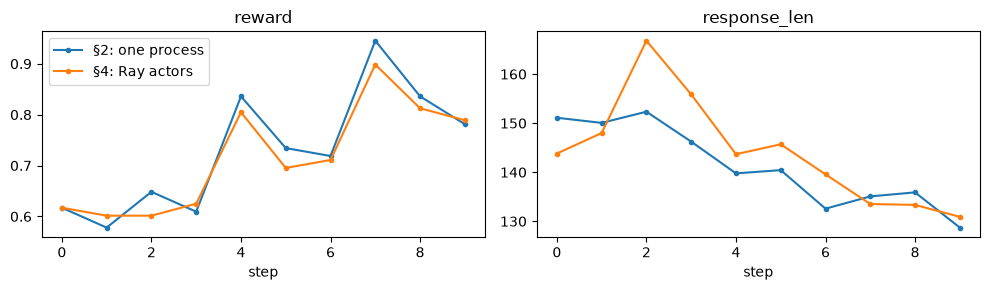

In [21]:
question_rng = random.Random(SEED)  # the same questions as the first steps of §2
ray_history = []

for step in range(10):
    problems = question_rng.sample(TRAIN, QUESTIONS_PER_STEP)
    metrics, last_batch = ray_rl_step(rollout_worker, training_worker, problems)
    ray_history.append(metrics)
    print_step_metrics(step, metrics)

plot_histories({"§2: one process": vllm_history[:10], "§4: Ray actors": ray_history}, keys=("reward", "response_len"))

As we can see, training behaves just as it did in a single process: over the same 10 batches of questions, the reward rises from about 0.6 to around 0.8–0.9 (as the samples are random, the numbers aren't identical), and each step takes about as long: around 0.7 s of generation, 2.2 s of update and 1.2 s of weight sync. Moving the work into separate processes has added very little overhead, as only the batch, the samples and the metrics travel through Ray.

So, what has Ray given us, even on a single GPU? The two roles are now independent processes, each with its own state and resources, and the training loop is a plain Python loop on the driver. If our cluster had more machines, the same code could place `RolloutWorker` and `TrainingWorker` on different ones.

What it hasn't given us yet is scale: each role is still a single process. A large policy doesn't fit on one GPU, and one vLLM engine can't generate thousands of samples quickly enough, so each role needs to become *many* processes, working together. That's the focus of the next section.

## 5. Many workers per role

When a role needs more than one GPU, it becomes a **worker group**: N actors of the same class, one per GPU, along with a rule for each method, which says how to split its input between the workers and how to combine their outputs. Two rules cover most of what a training loop needs:

![One-to-all: the driver sends the same call to every worker and gets back a list of results. Data-parallel: the batch is split into one chunk per worker, each worker processes its chunk, and the results are concatenated in order](images/worker_group.png)

* **One-to-all** sends the same call to every worker, and returns all of their results. This is used for setup and housekeeping, such as loading the model or saving a checkpoint.
* **Data-parallel** `chunk`s the `DataProto` into N pieces, gives one piece to each worker, and `concat`s their results back together, in order. This is used for the real work: computing log-probs, and updating the weights.

Workers that train the same model also need to talk to each other *directly*, many times per step, without going through the driver: for example, to share gradients, or to gather the pieces of a model that has been split across GPUs. This is a second channel, separate from Ray, and it's handled by `torch.distributed`. Each worker gets a **rank**, its number from 0 to N − 1, and the **world size**, N; they all connect to an agreed address to form a **process group**, and can then run **collectives**, such as `all_reduce`, where every worker contributes a tensor and every worker gets back their sum. FSDP, which splits a model's weights and optimizer state across GPUs, is built on these collectives, run over NCCL between GPUs. So, Ray handles the **control** (which process runs what), and `torch.distributed` handles the **data** that the workers exchange.

As we only have one GPU, we can't usefully run several GPU training workers here. Instead, let's build a worker group of CPU workers that compute rewards: a real job (verl also computes rewards in parallel workers), and cheap enough to show the pattern.

In [22]:
@ray.remote(num_cpus=1)
class ScoreWorker:
    def __init__(self, rank: int, model: str):
        self.rank = rank
        self.tokenizer = AutoTokenizer.from_pretrained(model)

    def info(self) -> dict:
        return {"rank": self.rank, "pid": os.getpid()}

    def score(self, data: DataProto) -> DataProto:
        texts = self.tokenizer.batch_decode(data.batch["responses"], skip_special_tokens=True)
        rewards = torch.tensor([reward_fn(text, int(answer)) for text, answer in zip(texts, data.non_tensor_batch["answer"])])
        return DataProto.from_dict(tensors={"reward": rewards}, non_tensors={"scored_by": np.full(len(data), self.rank, dtype=object)})


class MyWorkerGroup:
    def __init__(self, workers):
        self.workers = workers

    def one_to_all(self, method: str, *args):
        # Call the same method, with the same arguments, on every worker
        return ray.get([getattr(worker, method).remote(*args) for worker in self.workers])

    def data_parallel(self, method: str, data: DataProto) -> DataProto:
        # Split the batch into one chunk per worker, run the chunks in parallel, and concatenate the results
        chunks = data.chunk(len(self.workers))
        results = ray.get([getattr(worker, method).remote(chunk) for worker, chunk in zip(self.workers, chunks)])
        return DataProto.concat(results)

Let's create a group of 2 workers, and use it to score the last batch from §4:

In [23]:
score_group = MyWorkerGroup([ScoreWorker.remote(rank, MODEL) for rank in range(2)])
print("one_to_all('info'):", score_group.one_to_all("info"))

scored = score_group.data_parallel("score", last_batch)
driver_rewards = last_batch.batch["token_level_rewards"].sum(-1)
print(f"\nscored {len(scored)} rows; the same rewards as the driver computed: {torch.equal(scored.batch['reward'], driver_rewards)}")
print("rows scored by each worker:", pd.Series(scored.non_tensor_batch["scored_by"]).value_counts().sort_index().to_dict())

one_to_all('info'): [{'rank': 0, 'pid': 215896}, {'rank': 1, 'pid': 215895}]

scored 128 rows; the same rewards as the driver computed: True
rows scored by each worker: {0: 64, 1: 64}


As we can see, `one_to_all` reached both workers, each in its own process, and `data_parallel` split the 128 rows into 64 for each worker, and put the results back together in the right order, giving exactly the rewards that the driver computed.

#### verl's worker groups

verl packages this pattern up. Instead of choosing a rule each time we call a method, we **decorate each method with its rule**, known as its *dispatch mode*, when we write the worker class, which subclasses verl's `Worker`. `RayWorkerGroup` then starts one actor per slot in a `RayResourcePool`, sets each actor's rank, world size and process-group address in its environment, and gives the group a method of the same name, which splits, calls and gathers for us:

| Our version | verl's |
|---|---|
| `score_group.one_to_all("info")` | `@register(dispatch_mode=Dispatch.ONE_TO_ALL)`, then `group.info()` |
| `score_group.data_parallel("score", batch)` | `@register(dispatch_mode=Dispatch.DP_COMPUTE_PROTO)`, then `group.score(batch)` |
| `rank` passed in by hand | `self.rank`, `self.world_size`, read from the environment verl sets |
| `[ScoreWorker.remote(rank, ...) for rank in range(2)]` | `RayResourcePool(process_on_nodes=[2])` and `RayClassWithInitArgs` |

A resource pool reserves resources for each of its workers; with `use_gpu=True`, each worker gets one whole GPU. This is why we use CPU workers here (`use_gpu=False`): on our one GPU, a GPU pool could only hold a single worker.

In [24]:
from verl.single_controller.base import Worker
from verl.single_controller.base.decorator import Dispatch, register
from verl.single_controller.ray import RayClassWithInitArgs, RayResourcePool, RayWorkerGroup


class VerlScoreWorker(Worker):
    def __init__(self, model: str):
        super().__init__()
        self.tokenizer = AutoTokenizer.from_pretrained(model)

    @register(dispatch_mode=Dispatch.ONE_TO_ALL)
    def info(self) -> dict:
        return {"rank": self.rank, "world_size": self.world_size, "pid": os.getpid()}

    @register(dispatch_mode=Dispatch.DP_COMPUTE_PROTO)
    def score(self, data: DataProto) -> DataProto:
        texts = self.tokenizer.batch_decode(data.batch["responses"], skip_special_tokens=True)
        rewards = torch.tensor([reward_fn(text, int(answer)) for text, answer in zip(texts, data.non_tensor_batch["answer"])])
        return DataProto.from_dict(tensors={"reward": rewards}, non_tensors={"scored_by": np.full(len(data), self.rank, dtype=object)})

In [25]:
pool = RayResourcePool(process_on_nodes=[2], use_gpu=False, max_colocate_count=4)
verl_score_group = RayWorkerGroup(resource_pool=pool, ray_cls_with_init=RayClassWithInitArgs(cls=ray.remote(VerlScoreWorker), model=MODEL))
print("info():", verl_score_group.info())

verl_scored = verl_score_group.score(last_batch)
print(f"\nthe same rewards as our worker group: {torch.equal(verl_scored.batch['reward'], scored.batch['reward'])}")
print("rows scored by each worker:", pd.Series(verl_scored.non_tensor_batch["scored_by"]).value_counts().sort_index().to_dict())

info(): [{'rank': 0, 'world_size': 2, 'pid': 216361}, {'rank': 1, 'world_size': 2, 'pid': 216362}]

the same rewards as our worker group: True
rows scored by each worker: {0: 64, 1: 64}


verl's worker group gives exactly the same result as ours, and this pattern is the core of what verl calls its **single-controller** design: one driver process runs the training loop, and calls methods on worker groups, which do the heavy work. Its real workers are this same pattern, with much more inside:

* `ActorRolloutRefWorker` holds a slice of the policy, split across GPUs with FSDP or Megatron, along with its optimizer state and, in the colocated layout, a vLLM engine on the same GPU. Its `init_model` is one-to-all, whereas `compute_log_prob` and `update_actor` are data-parallel.
* The driver, `RayPPOTrainer.fit()`, is our `ray_rl_step` in a loop: it calls the worker groups in order, adds their results to the `DataProto`, and computes the advantages itself.

Going from 1 GPU to 64 changes the resource pools, not the training loop.

Let's stop the score workers, the two actors from §4 and Ray itself, as verl will start its own in the next section:

In [26]:
for worker in score_group.workers + list(verl_score_group.workers):
    ray.kill(worker)
ray.get(rollout_worker.shutdown.remote())  # stop vLLM's engine process before its actor goes away
ray.shutdown()
time.sleep(5)
print(f"GPU free: {gpu_free_gib():.0f} GiB")

GPU free: 92 GiB


## 6. A real framework running the whole loop

We have now built every part of a production training setup ourselves, at a small scale: an inference engine with weight sync, π_old recomputed by the training model, a batch container, separate processes for each role, and worker groups. So, let's hand our task to verl, and let it run the whole loop.

What we need to provide is the part that's specific to our task, in verl's format:

* **the reward**, as a function `compute_score(data_source, solution_str, ground_truth, extra_info)`, which calls our `reward_fn` on the decoded response;
* **the data**, as parquet files with one row per question: the chat `prompt`, a `data_source` name, and the answer in `reward_model.ground_truth`.

verl imports the reward function from a file, so we write it to one:

In [27]:
%%writefile tutorial/generated/verl_reward.py
import os
import sys

sys.path.insert(0, os.path.join(os.path.dirname(os.path.dirname(os.path.abspath(__file__))), "lib"))
from arith_task import reward_fn  # noqa: E402


def compute_score(data_source, solution_str, ground_truth, extra_info=None, **kwargs):
    return reward_fn(solution_str, int(ground_truth))

Overwriting tutorial/generated/verl_reward.py


Next, the data, and the command that launches verl's training. We use the same settings as our own training loop wherever there is an equivalent; the table below the cell maps each one back to what we built.

In [28]:
import datasets


def to_verl_rows(problems):
    rows = []
    for index, problem in enumerate(problems):
        rows.append({
            "data_source": "arith",
            "prompt": [{"role": "user", "content": f"{problem['question']} {INSTRUCTION}"}],
            "reward_model": {"style": "rule", "ground_truth": str(problem["answer"])},
            "extra_info": {"index": index},
        })
    return rows


datasets.Dataset.from_list(to_verl_rows(TRAIN[:512])).to_parquet(str(WORK / "arith_train.parquet"))
datasets.Dataset.from_list(to_verl_rows(EVAL[:64])).to_parquet(str(WORK / "arith_val.parquet"))

VERL_METRICS = WORK / "verl_metrics.jsonl"
VERL_METRICS.unlink(missing_ok=True)
verl_command = [
    sys.executable, "-m", "verl.trainer.main_ppo",
    "algorithm.adv_estimator=grpo",
    f"data.train_files={WORK / 'arith_train.parquet'}", f"data.val_files={WORK / 'arith_val.parquet'}",
    "data.train_batch_size=16", "data.max_prompt_length=256", "data.max_response_length=256", "data.dataloader_num_workers=0",
    f"actor_rollout_ref.model.path={MODEL}",
    "actor_rollout_ref.model.use_remove_padding=True", "actor_rollout_ref.model.enable_gradient_checkpointing=True",
    f"actor_rollout_ref.actor.optim.lr={LR}",
    "actor_rollout_ref.actor.ppo_mini_batch_size=8", "actor_rollout_ref.actor.ppo_micro_batch_size_per_gpu=16",
    "actor_rollout_ref.actor.use_kl_loss=False", "actor_rollout_ref.actor.entropy_coeff=0",
    "actor_rollout_ref.actor.clip_ratio_low=0.2", "actor_rollout_ref.actor.clip_ratio_high=0.28",
    "actor_rollout_ref.rollout.name=vllm", "actor_rollout_ref.rollout.tensor_model_parallel_size=1",
    "actor_rollout_ref.rollout.gpu_memory_utilization=0.4", "actor_rollout_ref.rollout.n=8",
    "actor_rollout_ref.rollout.log_prob_micro_batch_size_per_gpu=16",
    "actor_rollout_ref.rollout.agent.num_workers=2",
    f"reward.custom_reward_function.path={GENERATED / 'verl_reward.py'}", "reward.custom_reward_function.name=compute_score",
    "reward.num_workers=2",
    "trainer.n_gpus_per_node=1", "trainer.nnodes=1", "trainer.total_training_steps=10",
    "trainer.val_before_train=True", "trainer.test_freq=10", "trainer.save_freq=-1",
    "trainer.logger=[console,file]", "trainer.project_name=rl_training_series", "trainer.experiment_name=arith_verl",
    f"trainer.rollout_data_dir={WORK / 'verl_rollouts'}",
]
print(" \\\n  ".join(verl_command[2:]))


Creating parquet from Arrow format:   0%|          | 0/1 [00:00<?, ?ba/s]


Creating parquet from Arrow format: 100%|██████████| 1/1 [00:00<00:00, 272.78ba/s]


Creating parquet from Arrow format:   0%|          | 0/1 [00:00<?, ?ba/s]


Creating parquet from Arrow format: 100%|██████████| 1/1 [00:00<00:00, 2621.44ba/s]

verl.trainer.main_ppo \
  algorithm.adv_estimator=grpo \
  data.train_files=/tmp/rl-from-scratch/arith_train.parquet \
  data.val_files=/tmp/rl-from-scratch/arith_val.parquet \
  data.train_batch_size=16 \
  data.max_prompt_length=256 \
  data.max_response_length=256 \
  data.dataloader_num_workers=0 \
  actor_rollout_ref.model.path=Qwen/Qwen2.5-0.5B-Instruct \
  actor_rollout_ref.model.use_remove_padding=True \
  actor_rollout_ref.model.enable_gradient_checkpointing=True \
  actor_rollout_ref.actor.optim.lr=2e-06 \
  actor_rollout_ref.actor.ppo_mini_batch_size=8 \
  actor_rollout_ref.actor.ppo_micro_batch_size_per_gpu=16 \
  actor_rollout_ref.actor.use_kl_loss=False \
  actor_rollout_ref.actor.entropy_coeff=0 \
  actor_rollout_ref.actor.clip_ratio_low=0.2 \
  actor_rollout_ref.actor.clip_ratio_high=0.28 \
  actor_rollout_ref.rollout.name=vllm \
  actor_rollout_ref.rollout.tensor_model_parallel_size=1 \
  actor_rollout_ref.rollout.gpu_memory_utilization=0.4 \
  actor_rollout_ref.rollou

Every line of this config maps onto something we built, either in this article or the previous one:

| Config | What we built |
|---|---|
| `algorithm.adv_estimator=grpo` | `grpo_advantages` (§1.6 of the previous article), and verl's `compute_grpo_outcome_advantage` (its §2) |
| `actor.clip_ratio_low`/`high`, `ppo_mini_batch_size`, `ppo_micro_batch_size_per_gpu` | `ppo_clip_loss`, and `ppo_update`'s mini- and micro-batches (§1.7 and §1.9 of the previous article) |
| `rollout.name=vllm`, `gpu_memory_utilization`, `n` | `vllm_generate` and `RolloutWorker` (§1, §4) |
| `trainer.n_gpus_per_node`, `nnodes` | the resource pool (§5) |
| `reward.custom_reward_function`, `reward.num_workers` | `reward_fn`, run in a group of reward workers, like our `ScoreWorker`s (§5) |
| `model.use_remove_padding=True` | new: rather than padding rows into a rectangle (§1.7 of the previous article), verl packs the real tokens of every row into one long sequence, so no compute is spent on padding |

There is one thing to be careful of: the units. `data.train_batch_size=16` counts **prompts**: each step takes 16 questions, and `rollout.n=8` samples each of them 8 times, giving 128 samples. `ppo_mini_batch_size=8` also counts prompts, and verl multiplies it by `n` as well: 8 × 8 = 64 samples. So, each training step takes **two** optimizer steps, exactly as our loop in §2 did (128 samples, in mini-batches of 64). In contrast, `ppo_micro_batch_size_per_gpu` counts samples.

We'll train for 10 steps, and measure accuracy on 64 held-out questions before and after. Most of the time is spent starting up: Ray, the policy (wrapped in FSDP), and vLLM, which captures its CUDA graphs. Only selected lines of verl's log are printed here; the full log is in `/tmp/rl-from-scratch/logs/arith_verl.log`.

In [29]:
start_service("arith_verl", verl_command, cwd=WORK, env={"VERL_FILE_LOGGER_PATH": str(VERL_METRICS), "WANDB_MODE": "disabled"})
exit_code = follow_log("arith_verl", r"step:\d+ |Initial validation|Training Progress")
print(f"\nverl exited with code {exit_code}")
if exit_code != 0:
    raise RuntimeError(log_tail("arith_verl", 60))

started arith_verl (pid 217068), log: /tmp/rl-from-scratch/logs/arith_verl.log


[   89s] Training Progress:   0%|          | 0/10 [00:00<?, ?it/s]


[   95s] Training Progress:  10%|█         | 1/10 [00:06<00:54,  6.05s/it]


[   98s] (TaskRunner pid=220383) ("Initial validation metrics: {'val-aux/arith/reward/mean@1': "
[   98s] (TaskRunner pid=220383) step:0 - val-aux/arith/reward/mean@1:np.float64(0.71875) - val-core/arith/acc/mean@1:np.float64(0.71875) - val-aux/num_turns/min:np.int32(2) - val-aux/num_turns/max:np.int32(2) - val-aux/num_turns …
[   98s] (TaskRunner pid=220383) step:1 - global_seqlen/min:27226 - global_seqlen/max:27226 - global_seqlen/minmax_diff:0 - global_seqlen/balanced_min:27226 - global_seqlen/balanced_max:27226 - global_seqlen/mean:27226.0 - actor/ …


[   99s] Training Progress:  20%|██        | 2/10 [00:09<00:37,  4.69s/it]


[  103s] Training Progress:  30%|███       | 3/10 [00:13<00:30,  4.40s/it]
[  103s] (TaskRunner pid=220383) step:2 - global_seqlen/min:26214 - global_seqlen/max:26214 - global_seqlen/minmax_diff:0 - global_seqlen/balanced_min:26214 - global_seqlen/balanced_max:26214 - global_seqlen/mean:26214.0 - actor/ …
[  103s] (TaskRunner pid=220383) step:3 - global_seqlen/min:26145 - global_seqlen/max:26145 - global_seqlen/minmax_diff:0 - global_seqlen/balanced_min:26145 - global_seqlen/balanced_max:26145 - global_seqlen/mean:26145.0 - actor/ …


... (5 outputs left out)

[  125s] Training Progress:  90%|█████████ | 9/10 [00:35<00:03,  3.71s/it]
[  125s] (TaskRunner pid=220383) step:8 - global_seqlen/min:23799 - global_seqlen/max:23799 - global_seqlen/minmax_diff:0 - global_seqlen/balanced_min:23799 - global_seqlen/balanced_max:23799 - global_seqlen/mean:23799.0 - actor/ …
[  125s] (TaskRunner pid=220383) step:9 - global_seqlen/min:25289 - global_seqlen/max:25289 - global_seqlen/minmax_diff:0 - global_seqlen/balanced_min:25289 - global_seqlen/balanced_max:25289 - global_seqlen/mean:25289.0 - actor/ …


[  129s] Training Progress: 100%|██████████| 10/10 [00:40<00:00,  4.02s/it]


[  131s] (TaskRunner pid=220383) step:10 - global_seqlen/min:24712 - global_seqlen/max:24712 - global_seqlen/minmax_diff:0 - global_seqlen/balanced_min:24712 - global_seqlen/balanced_max:24712 - global_seqlen/mean:24712.0 - actor …



verl exited with code 0


verl logs a few hundred metrics at every step. Its file logger writes one JSON line per step, so let's read it back, and keep the metrics that correspond to the ones we printed in our own training loop (step 0 is the validation run before training):

In [30]:
def read_metrics(path: Path, patterns: list[str]) -> pd.DataFrame:
    # verl's file logger writes one JSON line per step; keep the metrics whose names match any pattern, in pattern order
    records = [json.loads(line) for line in path.read_text().splitlines()]
    all_names = sorted({name for record in records for name in record["data"]})
    keep = []
    for pattern in patterns:
        for name in all_names:
            if re.fullmatch(pattern, name) and name not in keep:
                keep.append(name)
    rows = [{"step": record["step"], **{name: record["data"].get(name) for name in keep}} for record in records]
    return pd.DataFrame(rows).groupby("step").last()


read_metrics(VERL_METRICS, [
    r"val-core/.*mean@1", r"critic/score/mean", r"actor/pg_loss", r"actor/grad_norm", r"actor/ppo_kl", r"actor/pg_clipfrac",
    r"actor/entropy", r"response_length/mean", r"timing_s/(gen|old_log_prob|update_actor|update_weights|step)",
]).T

step,0,1,2,3,4,5,6,7,8,9,10
val-core/arith/acc/mean@1,0.71875,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.859375
critic/score/mean,NaN,0.648438,0.625000,0.656250,0.562500,0.562500,0.781250,0.812500,0.703125,0.890625,0.781250
actor/pg_loss,NaN,0.075202,0.014968,0.058206,0.033142,0.038195,-0.001745,-0.010032,-0.050716,-0.002848,-0.012943
actor/grad_norm,NaN,2.290142,2.300860,2.306699,1.916382,1.236772,1.844229,1.602621,1.671337,1.392187,1.295140
actor/ppo_kl,NaN,-0.000067,0.000098,0.000178,0.000140,0.000213,0.000429,0.000476,0.000559,-0.000141,0.000176
actor/pg_clipfrac,NaN,0.000609,0.000195,0.001651,0.000444,0.001204,0.000768,0.000643,0.001196,0.000442,0.001044
actor/entropy,NaN,0.327785,0.295408,0.313306,0.226040,0.216779,0.175016,0.167047,0.151681,0.120306,0.116378
response_length/mean,NaN,154.953125,147.296875,146.882812,151.835938,170.421875,125.093750,127.437500,128.554688,139.820312,135.937500
timing_s/gen,NaN,1.300089,1.046457,1.051880,1.055490,1.081467,0.985898,1.031287,0.985362,1.001673,0.953244
timing_s/old_log_prob,NaN,2.132536,0.483462,0.485199,0.468692,0.497782,0.464199,0.463210,0.458199,0.461995,0.455721


Each of these is something we have already computed ourselves:

| Metric | What it tells us | Ours |
|---|---|---|
| `val-core/…/mean@1` | greedy accuracy on held-out questions: the number we really care about | `evaluate` |
| `critic/score/mean` | the mean reward of the step's samples (verl logs it under `critic/`, even without a critic) | `reward` |
| `actor/pg_loss`, `actor/grad_norm` | the update itself; the loss value means little on its own, as it's the gradient that matters | `ppo_update` |
| `actor/ppo_kl`, `actor/pg_clipfrac` | how far the policy moved during the step, and the fraction of tokens outside the clip range | `ratio_min`/`ratio_max` and `clip_fraction` from `ppo_update` |
| `actor/entropy` | how spread out the policy's next-token distribution is; if it collapses, the model has stopped exploring | (not measured) |
| `response_length/mean` | how the model's responses are changing | `len` |
| `timing_s/*` | where the time goes: generation, π_old, the update, and the weight sync | the timings in `rl_step` |

Reading the table, we see the same picture as in our own training loop:

* accuracy on the 64 held-out questions went from 0.72 to 0.86, and the training reward rose from about 0.65 to around 0.8–0.9, noisily;
* `actor/ppo_kl` and `actor/pg_clipfrac` are small, but not zero: each step takes two optimizer steps, and on the second, the ratio is no longer 1. Only about 0.1% of tokens were clipped, in line with what we saw in §1.9 of the previous article;
* `actor/entropy` falls from about 0.33 to 0.12, as the model becomes more confident in its choices. Some fall is expected as it learns, but if entropy collapses towards 0, the model stops exploring, and GRPO's groups stop containing different answers to compare;
* after the first step, which includes some warm-up, each step takes about 3.7 s: about 1 s generating, 0.5 s on π_old, 1.4 s updating and 0.8 s syncing the weights. Its update is about twice as fast as ours, probably helped by packing the sequences without padding, and its weight sync skips the round trip through the CPU; its generation is a little slower, as it goes through more machinery than our single `llm.generate` call.

The whole run took a little over 2 minutes, most of which was spent starting up. For a 10-step run, that's a large overhead, but for a real run of thousands of steps, it hardly matters.

`trainer.rollout_data_dir` also makes verl save every sample it generated, along with its score, one file per step. Let's look at the training scores step by step, and one response from the last step:

In [31]:
def step_number(path: Path) -> int:
    return int(path.stem)


rollout_files = sorted((WORK / "verl_rollouts").glob("*.jsonl"), key=step_number)  # one file per training step
for path in rollout_files:
    scores = [json.loads(line)["score"] for line in path.read_text().splitlines()]
    print(f"training step {path.stem:>2}: {len(scores)} samples, mean score {np.mean(scores):.2f}")

example = json.loads(rollout_files[-1].read_text().splitlines()[0])
print("\n" + "─" * 100 + "\n" + example["output"] + f"\n{'─' * 100}\nground truth {example['gts']} | score {example['score']}")

training step  1: 128 samples, mean score 0.65
training step  2: 128 samples, mean score 0.62
training step  3: 128 samples, mean score 0.66
training step  4: 128 samples, mean score 0.56
training step  5: 128 samples, mean score 0.56
training step  6: 128 samples, mean score 0.78
training step  7: 128 samples, mean score 0.81
training step  8: 128 samples, mean score 0.70
training step  9: 128 samples, mean score 0.89
training step 10: 128 samples, mean score 0.78

────────────────────────────────────────────────────────────────────────────────────────────────────
To solve the expression \(4 + 4 - 6\), we can work through it step by step:

1. Start with the sum: \(4 + 4 = 8\)
2. Subtract 6 from the result: \(8 - 6 = 2\)

So, the final answer is \(\boxed{2}\).
────────────────────────────────────────────────────────────────────────────────────────────────────
ground truth 2 | score 1.0


The scores for each step match `critic/score/mean` in the table above, and the response is what we'd hope for: brief working, then the answer in `\boxed{}`. In a real run, these files are often the most useful thing to look at: when a metric moves unexpectedly, reading what the model actually wrote is usually the quickest way to find out why.

## What we built

Over this article, we have taken our training loop apart into the pieces that production RL setups are built from, built each one ourselves, and then let verl run the whole thing:

| Problem | Solution | Ours | verl's |
|---|---|---|---|
| generation takes up most of each step | a dedicated inference engine, with RL sampling settings | `vllm_generate` | vLLM, started by verl with its sampling defaults overridden |
| the inference engine has its own copy of the weights | push the weights after every update, and reset the prefix cache | `push_weights` | GPU-to-GPU transfer over CUDA IPC or NCCL |
| the two copies compute slightly different log-probs | recompute π_old with the training model, and monitor the gap | `compute_log_probs`, `logp_mismatch` | `compute_log_prob`, `rollout_corr/kl` |
| each step's data has to travel between processes | a batch container that keeps each row together | `DataProto` | `DataProto` |
| the roles need different resources and lifetimes | one process per role, and a driver that runs the loop | Ray actors, `ray_rl_step` | `RayPPOTrainer.fit()` |
| one process per role isn't enough | worker groups, with one rule per method for splitting the work | `MyWorkerGroup` | `RayWorkerGroup`, `@register(Dispatch...)` |

For a single-turn task like ours, that's the whole story: with verl, the only code we needed to write was the reward function and the data.

**Next steps:** there is one stage of the training step that we haven't questioned yet: where the samples come from. So far, every sample has been a single response to a single prompt. Agents work differently: they call tools, read the results, and carry on over many turns, and they are often programs that already exist, with their own code and their own way of talking to the model. That is the subject of the next article.

In [32]:
shutil.rmtree(SHM, ignore_errors=True)  # the weights we wrote for vLLM
print(f"GPU free: {gpu_free_gib():.0f} GiB")

GPU free: 92 GiB
